In [1]:
import pandas as pd
import numpy as np
from itertools import  product
import matplotlib.pyplot as plt

In [2]:
def get_n_qtr_fwd_bwd(cq,nq,forward=True,leading_zeros=True):
    cy = int(cq.split("FY")[1])
    cqn = int(cq[1])
    if leading_zeros:
        l = [
            f"Q{i % 4 + 1}FY{(cy + (i // 4)) % 100:02d}"  # Format year to have leading zeros
            for i in range(cqn, cqn + nq)
        ] if forward else [
            f"Q{i % 4 + 1}FY{(cy + (i // 4)) % 100:02d}"  # Format year to have leading zeros
            for i in range(cqn - nq, cqn - 1)
        ]
    else:
        l = [f"Q{i % 4 + 1}FY{cy + (i // 4)}" for i in range(cqn, cqn+nq)] if forward==True else [f"Q{i % 4 + 1}FY{cy + (i // 4)}" for i in range(cqn-nq,cqn-1)]  
    return l
def get_nth_qtr_fwd_bwd(cq, nq, forward=True,leading_zeros=True):
    cy = int(cq.split("FY")[1])
    cqn = int(cq[1])
    if not forward:
        nq = -nq
    new_qn = (cqn - 1 + nq) % 4 + 1
    new_cy = cy + (cqn - 1 + nq) // 4
    if leading_zeros:
        new_cy = f"{new_cy}" if new_cy >=10 else f"0{new_cy}"
    else:
        new_cy = f"{new_cy}"
    return f"Q{new_qn}FY{new_cy}"

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
df_upto_fy24 = pd.read_excel(r"D:\FY25-26\Quant Fund\data\Raw_Data_Q4FY05_Q4FY24.xlsx")

df_q1fy25 = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stocks_data_Q1FY25_formatted.xlsx")
df_q2fy25 = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stocks_data_Q2FY25_formatted.xlsx")
df_q3fy25 = pd.read_excel(r"D:\FY25-26\Quant Fund\data\Q3FY25 Stocks formatted cols data.xlsx",sheet_name='Main')

q1fy25_cols = [x for x in df_q1fy25.columns if "Q1FY25" in x]

df_q1fy25_1 = df_q1fy25[q1fy25_cols+['Ticker']].rename(columns={'Mcap_Q1FY25':'Mkt_Cap_Q1FY25','MA_200D_Q1FY25':'200D_MVA_Q1FY25','MA_50D_Q1FY25':'50D_MVA_Q1FY25','Div_Yield_Q1FY25':'Dividend_Q1FY25',
                                  'Rev_Q1FY25':'Revenue_Q1FY25','AssetTurn_Q1FY25':'Ast_TO_Q1FY25'})

df_q2fy25['Ticker'] = df_q2fy25['Ticker'].apply(lambda x: x.replace(" Equity ",""))
df_q12fy25 = df_q1fy25_1.merge(df_q2fy25,on='Ticker',how='left')

df_q3fy25.rename(columns={'P/B_Q2FY25':'P/B_Q3FY25'},inplace=True)
df_q3fy25['Ticker'] = df_q3fy25['Ticker'].apply(lambda x: x.split(" Equity")[0])
df_q3fy25.drop(columns=['Long Company Name'],inplace=True)
df_q123fy25 = df_q12fy25.merge(df_q3fy25,how='left',on='Ticker')


In [4]:
df_upto_fy24['Ticker']= df_upto_fy24['Ticker'].astype(str).apply(lambda x:x.split(" Equity")[0])

In [5]:
df2 = df_upto_fy24.merge(df_q123fy25,on='Ticker',how='left')
df2.head()

,Ticker,Mkt_Cap_Q4FY05,Mkt_Cap_Q1FY06,Mkt_Cap_Q2FY06,Mkt_Cap_Q3FY06,Mkt_Cap_Q4FY06,Mkt_Cap_Q1FY07,Mkt_Cap_Q2FY07,Mkt_Cap_Q3FY07,Mkt_Cap_Q4FY07,...,Revenue_Q3FY25,EBITDA_Q3FY25,NI_Q3FY25,Abn_Gain_Loss_Q3FY25,CFO_Q3FY25,ROE_Q3FY25,ROA_Q3FY25,ROCE_Q3FY25,D/E_Q3FY25,Ast_TO_Q3FY25
0,NSEMCAP,NaN,NaN,2.572796e+06,NaN,3.239589e+06,2.715494e+06,3.204301e+06,3.561119e+06,3.406560e+06,...,-,287.811591,-,-,NaN,0.121606,0.021214,-,146.380119,-
1,RELIANCE IN,760925.0743,895398.6018,1.105818e+06,NaN,1.108327e+06,1.476910e+06,1.632843e+06,1.769964e+06,1.909524e+06,...,239986,45202,18540,0,91810.00,0.086481,0.038839,0.116737,37.463692,0.528938
2,TCS IN,684913.7050,652043.9196,7.116982e+05,NaN,9.372641e+05,8.507794e+05,1.000189e+06,1.195862e+06,1.207459e+06,...,63973,17033,12380,-100,21999.00,0.459653,0.29622,0.497375,8.655465,1.552826
3,HDFCB IN,156345.3626,197972.7171,2.137217e+05,NaN,2.422794e+05,2.498088e+05,2.909067e+05,3.365638e+05,3.016875e+05,...,112193.94,-,17656.61,-,113799.72,0.153614,0.017441,-,133.948579,0.120472
4,BHARTI IN,384388.3041,455406.3639,6.550441e+05,NaN,7.814905e+05,7.010804e+05,8.894564e+05,1.194224e+06,1.448254e+06,...,45129.3,24596.6,14781.2,-75456,46734.10,0.149068,0.027167,0.342255,204.473858,0.34433


In [6]:
df2['Ticker'] = df2['Ticker'].apply(lambda x:x.split(" Equity")[0])

In [7]:
# Validation
len(set([x.split("_Q")[0] for x in df2.columns])-set([x.split("_Q")[0] for x in df_upto_fy24.columns]))
len(set([x.split("_Q")[0] for x in df_upto_fy24.columns])-set([x.split("_Q")[0] for x in df2.columns]))

0

In [8]:
set([x.split("_Q")[0] for x in df2.columns])

{'200D_MVA',
 '50D_MVA',
 'Abn_Gain_Loss',
 'Ast_TO',
 'CFO',
 'D/E',
 'Dividend',
 'EBITDA',
 'Mkt_Cap',
 'NI',
 'P/B',
 'P/E',
 'Price',
 'ROA',
 'ROCE',
 'ROE',
 'Revenue',
 'Ticker',
 'Volume'}

In [9]:
#### Calculating Percentages
perc_changes = ['Price' ,'Revenue','EBITDA', 'NI','Abn_Gain_Loss','200D_MVA','50D_MVA','Dividend','CFO','Volume']
ratios = ['P/E', 'P/B','ROE', 'ROA','ROCE', 'D/E', 'Ast_TO','Mkt_Cap']

In [10]:
df2.replace(['-',np.inf,-np.inf,'#N/A Field Not Applicable'],np.nan,inplace=True)
for col in df2.columns:
    # df2[col].replace(['-',-np.inf,np.inf],np.NAN,inplace=True)
    if col not in  ['Ticker']:
        df2[col] = df2[col].astype(float)

C:\Users\35098\AppData\Local\Temp\ipykernel_20688\485265441.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df2.replace(['-',np.inf,-np.inf,'#N/A Field Not Applicable'],np.nan,inplace=True)


In [11]:
for feature in perc_changes:
    qc = 'Q4FY05'
    while get_nth_qtr_fwd_bwd(qc,nq=1,leading_zeros=True) != 'Q4FY25':
        qnq = get_nth_qtr_fwd_bwd(qc,nq=1,leading_zeros=True)
        qny = get_nth_qtr_fwd_bwd(qc,nq=4,leading_zeros=True)
        qnq1 = feature+"_"+qnq
        qc1 = feature+"_"+qc
        qny1 = feature+"_"+qny
        if (qnq1 in df2.columns)&(qc1 in df2.columns):
                # df2[qnq1].replace(['-',np.inf,-np.inf],np.NAN).astype(float)
                # df2[qc1].replace(['-',np.inf,-np.inf],np.NAN,inplace=True)
                df2[f'{feature}_QoQ_growth_{qnq}'] = (
                    (df2[qnq1].divide(df2[qc1]) - float(1)) * 100
                )

            # YoY growth
        if (qny1 in df2.columns)&(qc1 in df2.columns):
            # df2[qny1].replace(['-',np.inf,-np.inf],np.NAN,inplace=True)
            # df2[qc1].replace(['-',np.inf,-np.inf],np.NAN,inplace=True)
            df2[f'{feature}_YoY_growth_{qny}'] = (
                (df2[qny1].divide(df2[qc1]) - float(1)) * 100
            )
        qc = get_nth_qtr_fwd_bwd(qc,nq=1,leading_zeros=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_20688\2891587733.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df2[f'{feature}_QoQ_growth_{qnq}'] = (
C:\Users\35098\AppData\Local\Temp\ipykernel_20688\2891587733.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df2[f'{feature}_YoY_growth_{qny}'] = (
C:\Users\35098\AppData\Local\Temp\ipykernel_20688\2891587733.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider join

In [12]:
perc_changes1 = []
for x, y in product(perc_changes,["_QoQ_growth_",'_YoY_growth_']):
    perc_changes1.append(x+y)

ratios1 = []
for x, y in product(ratios,['_']):
    ratios1.append(x+y)

In [13]:
stock_cols = perc_changes1+ratios1

In [14]:
df2.columns

Index(['Ticker', 'Mkt_Cap_Q4FY05', 'Mkt_Cap_Q1FY06', 'Mkt_Cap_Q2FY06',
       'Mkt_Cap_Q3FY06', 'Mkt_Cap_Q4FY06', 'Mkt_Cap_Q1FY07', 'Mkt_Cap_Q2FY07',
       'Mkt_Cap_Q3FY07', 'Mkt_Cap_Q4FY07',
       ...
       'Volume_YoY_growth_Q4FY24', 'Volume_QoQ_growth_Q2FY24',
       'Volume_YoY_growth_Q1FY25', 'Volume_QoQ_growth_Q3FY24',
       'Volume_YoY_growth_Q2FY25', 'Volume_QoQ_growth_Q4FY24',
       'Volume_YoY_growth_Q3FY25', 'Volume_QoQ_growth_Q1FY25',
       'Volume_QoQ_growth_Q2FY25', 'Volume_QoQ_growth_Q3FY25'],
      dtype='object', length=2991)

In [15]:
all_qtrs = get_n_qtr_fwd_bwd("Q3FY06",76,True,True)
# all_qtrs

In [16]:
price_cols = []
for x,y in product(['Price_'],all_qtrs):
    price_cols.append(x+y)
price_cols[:8]

['Price_Q4FY06',
 'Price_Q1FY07',
 'Price_Q2FY07',
 'Price_Q3FY07',
 'Price_Q4FY07',
 'Price_Q1FY08',
 'Price_Q2FY08',
 'Price_Q3FY08']

In [17]:
listing_dict = {}
for index, row in df2.iterrows():
    for x,y in product(['Price_'],get_n_qtr_fwd_bwd("Q3FY05",80,True,True)):
        col = x+y
        if row[col] > 0:
            listing_qtr = y
            listing_dict[row['Ticker']] = listing_qtr
            break

In [18]:
df_listing  = pd.DataFrame.from_dict(listing_dict,orient='index').reset_index(drop=False).rename(columns={'index':'Ticker',0:'listing_qtr'})

In [19]:
df_listing['listing_qtr'].value_counts()

listing_qtr
Q4FY05    507
Q2FY24     24
Q3FY22     21
Q3FY24     20
Q2FY22     18
         ... 
Q2FY13      2
Q1FY12      1
Q4FY09      1
Q2FY09      1
Q1FY10      1
Name: count, Length: 74, dtype: int64

In [20]:
df_listing

,Ticker,listing_qtr
0,NSEMCAP,Q4FY05
1,RELIANCE IN,Q4FY05
2,TCS IN,Q4FY05
3,HDFCB IN,Q4FY05
4,BHARTI IN,Q4FY05
...,...,...
1035,YASHO IN,Q1FY19
1036,GOCL IN,Q4FY05
1037,MBAP IN,Q2FY17
1038,JIND IN,Q4FY11


In [21]:
tickers_with_lesser_data = df2[df2.merge(df_listing,on='Ticker',how='left')['listing_qtr'].isna()]['Ticker'].unique()

In [22]:
l = [x for x in df2.columns if 'Price_Q' in x]

In [23]:
df2[df2['Ticker'] == 'JNKINDIA IN'][l]

,Price_Q4FY05,Price_Q1FY06,Price_Q2FY06,Price_Q3FY06,Price_Q4FY06,Price_Q1FY07,Price_Q2FY07,Price_Q3FY07,Price_Q4FY07,Price_Q1FY08,...,Price_QoQ_growth_Q2FY23,Price_QoQ_growth_Q3FY23,Price_QoQ_growth_Q4FY23,Price_QoQ_growth_Q1FY24,Price_QoQ_growth_Q2FY24,Price_QoQ_growth_Q3FY24,Price_QoQ_growth_Q4FY24,Price_QoQ_growth_Q1FY25,Price_QoQ_growth_Q2FY25,Price_QoQ_growth_Q3FY25
815,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-20.053089,-49.532146


In [24]:
df2[df2['Ticker'] == 'JNKINDIA IN'].isna().sum(axis=1)

815    2922
dtype: int64

In [25]:
df2.shape

(1044, 2991)

In [26]:
df2[df2['Ticker'].isin(tickers_with_lesser_data)].isna().sum(axis=1)

490    2831
513    2889
527    2809
551    2827
dtype: int64

In [27]:
df_2 = df2.merge(df_listing,on='Ticker',how='left')

In [28]:
df3 = df_2[~df_2['Ticker'].isin(tickers_with_lesser_data)]

In [29]:
# df3[df3['listing_qtr']=='Q2FY22']

In [30]:
df3 = df_2[~df_2['listing_qtr'].isna()]

In [31]:
df3.head()

,Ticker,Mkt_Cap_Q4FY05,Mkt_Cap_Q1FY06,Mkt_Cap_Q2FY06,Mkt_Cap_Q3FY06,Mkt_Cap_Q4FY06,Mkt_Cap_Q1FY07,Mkt_Cap_Q2FY07,Mkt_Cap_Q3FY07,Mkt_Cap_Q4FY07,...,Volume_QoQ_growth_Q2FY24,Volume_YoY_growth_Q1FY25,Volume_QoQ_growth_Q3FY24,Volume_YoY_growth_Q2FY25,Volume_QoQ_growth_Q4FY24,Volume_YoY_growth_Q3FY25,Volume_QoQ_growth_Q1FY25,Volume_QoQ_growth_Q2FY25,Volume_QoQ_growth_Q3FY25,listing_qtr
0,NSEMCAP,NaN,NaN,2.572796e+06,NaN,3.239589e+06,2.715494e+06,3.204301e+06,3.561119e+06,3.406560e+06,...,39.677474,274.327613,231.100059,30.197021,-53.461326,-71.398651,73.921083,-51.417982,-27.264784,Q4FY05
1,RELIANCE IN,760925.0743,895398.6018,1.105818e+06,NaN,1.108327e+06,1.476910e+06,1.632843e+06,1.769964e+06,1.909524e+06,...,16.314712,-41.481587,-0.671118,120.297205,80.702354,-77.390371,-71.970295,337.875959,-89.805639,Q4FY05
2,TCS IN,684913.7050,652043.9196,7.116982e+05,NaN,9.372641e+05,8.507794e+05,1.000189e+06,1.195862e+06,1.207459e+06,...,-16.917436,-10.052433,-27.782750,9.827684,161.335319,40.981385,-42.635862,1.445385,-7.297618,Q4FY05
3,HDFCB IN,156345.3626,197972.7171,2.137217e+05,NaN,2.422794e+05,2.498088e+05,2.909067e+05,3.365638e+05,3.016875e+05,...,-24.803489,-5.854165,-17.261626,-14.214896,115.791802,-78.074695,-29.876837,-31.481403,-78.853390,Q4FY05
4,BHARTI IN,384388.3041,455406.3639,6.550441e+05,NaN,7.814905e+05,7.010804e+05,8.894564e+05,1.194224e+06,1.448254e+06,...,-76.650757,-66.839834,-7.825030,30.301327,102.191860,-30.019927,-23.797852,-8.250237,-50.496197,Q4FY05


In [32]:
params_set = set([x.split("_")[0] for x in df3.columns])

In [33]:
dict1 = {}
for x in params_set:
    if x != 'Ticker':
        l = ['Ticker']+[y for y in df3.columns if x in y and "growth" not in y]
        dict1[x] = l

In [34]:
dict2 = {}
for key,val in dict1.items():
    dict2[key] = df3[val]

In [35]:
dict2.keys()

dict_keys(['listing', 'P/E', 'EBITDA', 'ROA', 'CFO', 'Mkt', 'Price', 'Abn', 'Ast', '200D', 'Dividend', 'D/E', 'P/B', 'Revenue', 'NI', 'ROE', 'ROCE', '50D', 'Volume'])

In [37]:
# for key,val in dict2.items():
#     df_temp = val.copy()
#     cols1 = list(df_temp.set_index(keys=['Ticker']).columns)
#     cols2 = [x[-6:] for x in cols1]
#     # print(cols2)
#     dict_map = dict(zip(cols1,cols2))
#     df_temp.rename(columns=dict_map,inplace=True)
#     df_temp.to_excel(rf"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\{key.replace('/','_')}.xlsx",index=False)

In [38]:
# with pd.ExcelWriter(r"D:\FY25-26\Quant Fund\data\Param_Wise_Qtrly_Data_last20Yrs.xlsx") as writer:
#     for key,val in dict2.items():
#         val.to_excel(writer,sheet_name=key.replace("/","_"),index=False)

In [43]:
# df_fin = pd.DataFrame()
# for ticker in df3['Ticker'].unique():
#     if ticker != 'NSEMCAP':
#         df_temp = df3[df3['Ticker'] == ticker]

#         qtrs_list_listing = get_n_qtr_fwd_bwd("Q3FY05",80,True,True)
#         df_temp_stock = pd.DataFrame()
#         temp_listing_qtr = df_temp['listing_qtr'].values[0]
#         qtr_ind = qtrs_list_listing.index(temp_listing_qtr)
#         iterable_qtrs = qtrs_list_listing[qtrs_list_listing.index('Q4FY06'):] if qtr_ind<4 else qtrs_list_listing[qtr_ind:]

#         for qtr in iterable_qtrs:
#             cols_qtr = [x+qtr for x in stock_cols]
#             tgt_qtr = get_nth_qtr_fwd_bwd(qtr,1,True,True)
#             tgt_price_grth = f'Price_QoQ_growth_{tgt_qtr}'
#             cols_qtr.append(tgt_price_grth)

#             cols_not_available = list(set(cols_qtr)-set(df_temp.columns))

#             d = {}
#             for i in cols_qtr:
#                 if i in cols_not_available:
#                     d[i] = float(np.nan)
#                 else:
#                     d[i] = df_temp[i].values[0]

#             df_temp1 = pd.DataFrame(d,index=[0])
#             df_temp1['Ticker'] = ticker
#             df_temp1['Quarter'] = qtr
#             stock_cols_processed = [x[:-1] for x in stock_cols]
#             stock_cols_processed1 = stock_cols_processed+['Returns','Ticker','Quarter']
#             rename_cols_dict = dict(zip(df_temp1.columns,stock_cols_processed1))
#             df_temp1.rename(columns=rename_cols_dict,inplace=True)
#             df_temp_stock = pd.concat([df_temp_stock,df_temp1],axis=0)
#         df_fin = pd.concat([df_fin,df_temp_stock],axis=0)

In [44]:
# df_fin.head(2)

In [45]:
# df_fin.columns

In [46]:
# df_fin.reset_index(drop=True,inplace=True)

In [47]:
# df_fin1 = df_fin.groupby('Quarter').apply(lambda x: x.nlargest(200, 'Mkt_Cap')).reset_index(drop=True)

In [48]:
# df_fin_1 = df_fin1[~df_fin1['Returns'].isna()].reset_index(drop=True)

In [49]:
# df_fin_1['Target'] = df_fin_1.groupby('Quarter')['Returns'].transform(lambda x: x.rank(ascending=False) <= 30).astype(int)

In [50]:
# df_fin_1.groupby("Quarter")['Returns'].rank().isna().sum()

In [51]:
# df_fin_1['Rank'] = df_fin_1.groupby("Quarter")['Returns'].rank(ascending=False)

In [40]:
# df_fin_1.to_excel(r"D:\FY25-26\Quant Fund\data\formatted_ts_data_25_05_2025.xlsx",index=False)

In [52]:
d = pd.Series(df2[[x for x in df2.columns if 'D/E' in x]].isna().sum())

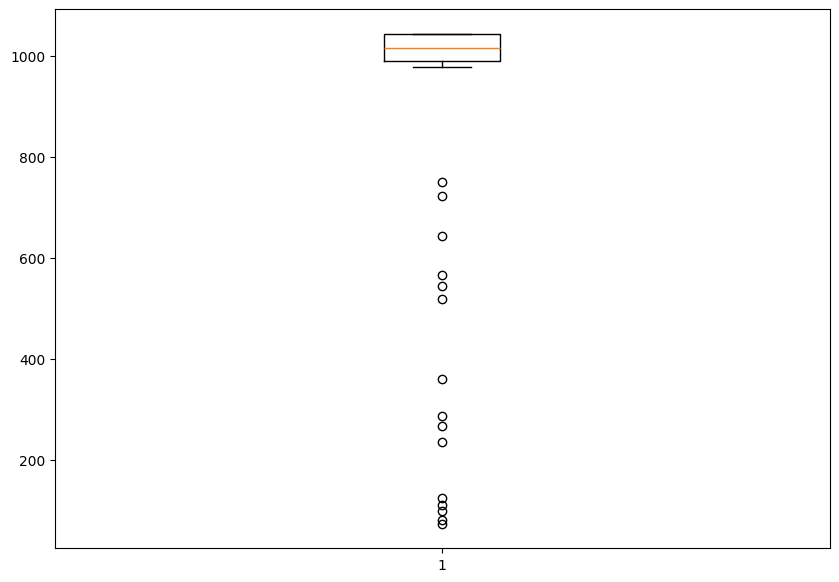

In [53]:
fig = plt.figure(figsize =(10, 7))

plt.boxplot(d)
plt.show()

In [48]:
d = pd.Series(df2[[x for x in df2.columns if 'ROA' in x]].isna().sum())

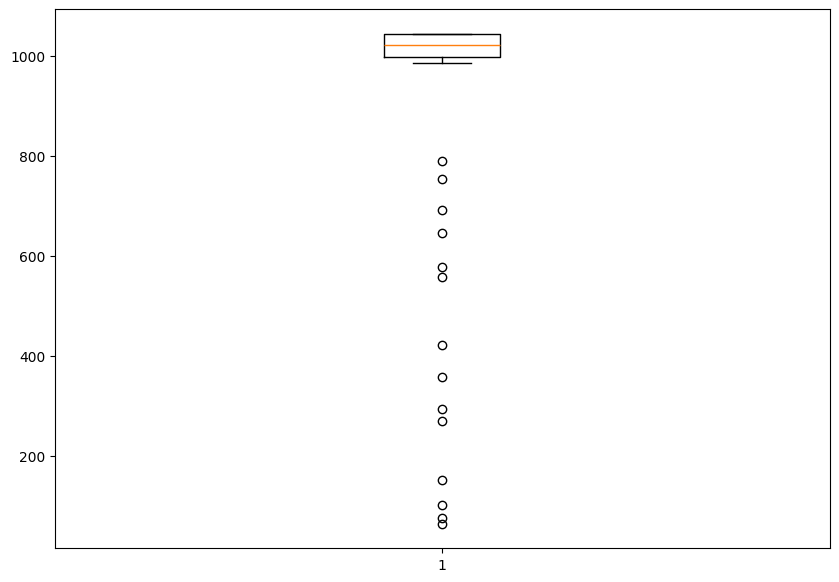

In [49]:
fig = plt.figure(figsize =(10, 7))

plt.boxplot(d)
plt.show()

In [50]:
d = pd.Series(df2[[x for x in df2.columns if 'ROE' in x]].isna().sum())

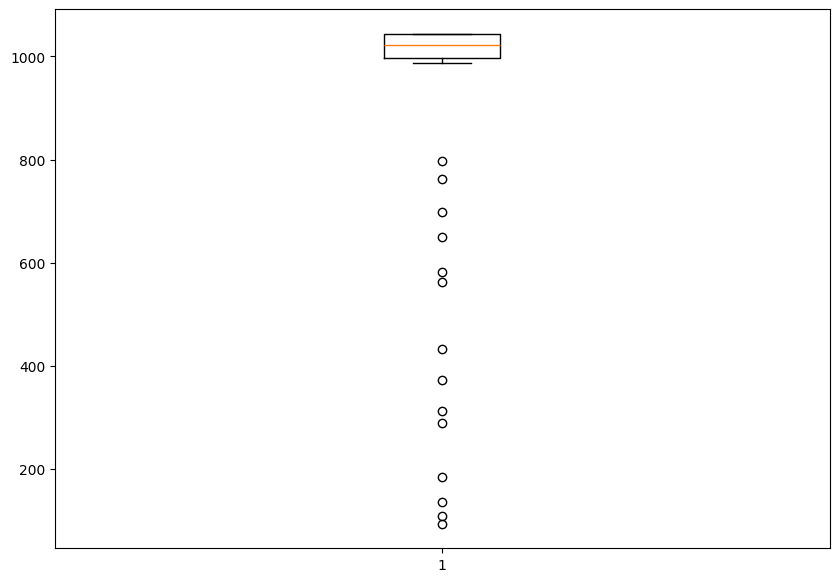

In [51]:
fig = plt.figure(figsize =(10, 7))

plt.boxplot(d)
plt.show()

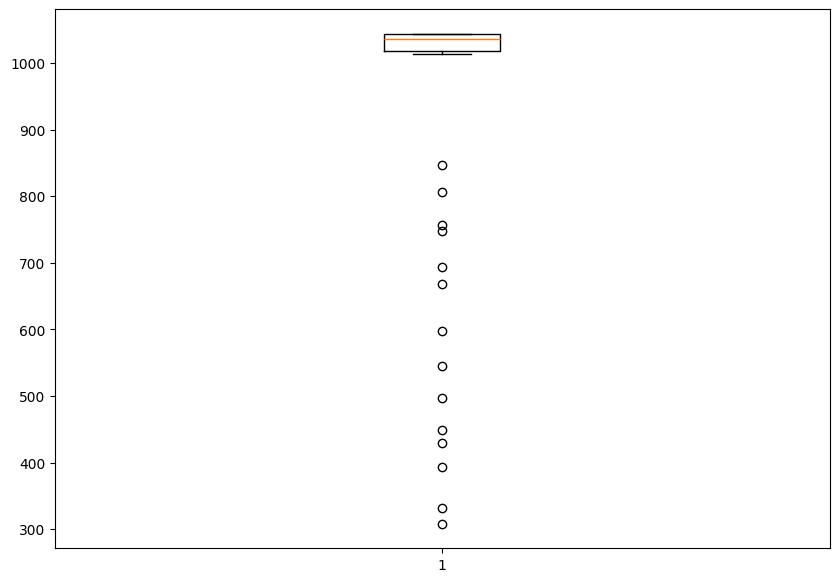

In [52]:
d = pd.Series(df2[[x for x in df2.columns if 'ROCE' in x]].isna().sum())
fig = plt.figure(figsize =(10, 7))

plt.boxplot(d)
plt.show()

In [54]:
df_listing.to_clipboard()